# Visualizar Bodega de datos 

## 1. Cargar Librerias

In [1]:
!pip install matplotlib
!pip install seaborn



In [2]:
# Import the neccessary modules for data manipulation and visual representation
import pandas as pd
import numpy as np
import matplotlib as plt
import matplotlib.pyplot as plt
import matplotlib as matplot
import seaborn as sns
from matplotlib.pyplot import figure
%matplotlib inline

import string
from sqlalchemy import create_engine
import psycopg2
import pandas as pd
import io
import os
from dotenv import load_dotenv



## 2. Conectar Python con PostgreSQL

In [3]:
from importlib import reload
import conexion
reload(conexion)

<module 'conexion' from '/Users/raul.alzate/Documents/maestria/maestria/data_science/taller1/conexion.py'>

## 3. Comprobar la conexion a la bodega de datos

In [4]:
from sqlalchemy import text

# consulta sobre la tabla dim_tiempo
sql_dim_tiempo = 'select * from dim_tiempo'
sql_dim_estacion = 'select * from dim_estacion'
sql_dim_polutante = 'select * from dim_polutante'
sql_fact_medidad = 'select * from fact_medidad'

# Use the existing engine and sqlalchemy.text to execute a SELECT.
# No commit is needed for SELECT statements.
with conexion.engine.connect() as connection:
    result = connection.execute(text(sql_dim_tiempo))
    df_tiempo = pd.DataFrame(result.fetchall(), columns=result.keys())
    result = connection.execute(text(sql_dim_estacion))
    df_estacion = pd.DataFrame(result.fetchall(), columns=result.keys())
    result = connection.execute(text(sql_dim_polutante))
    df_polutante = pd.DataFrame(result.fetchall(), columns=result.keys())
    result = connection.execute(text(sql_fact_medidad))
    df_medidad = pd.DataFrame(result.fetchall(), columns=result.keys())


print(df_tiempo.head())
print("\n")
print(df_estacion.head())
print("\n")
print(df_polutante.head())
print("\n")
print(df_medidad.head())


# compruebe con otras tablas como dim_estacion, dim_polutante, fact_medidad



   id  dia  mes    anho  hora  fin_semana  festivo
0   1  1.0  1.0  2021.0   1.0       False     True
1   2  1.0  1.0  2021.0   2.0       False     True
2   3  1.0  1.0  2021.0   3.0       False     True
3   4  1.0  1.0  2021.0   4.0       False     True
4   5  1.0  1.0  2021.0   5.0       False     True


   id        Name Sigla   Localidad   Latitud   Longitud
0   1       usame   USM        Usme  4.532097 -74.116947
1   2     bolivia   BOL    Engativá  4.735578 -74.125925
2   3        suba   SUB        Suba  4.761222 -74.093433
3   4       tunal   TUN  Tunjuelito  4.576206 -74.130975
4   5  las_ferias   LFR    Engativá  4.690628 -74.082378


   id   PM10  PM2.5      NO     NO2     NOX       CO  OZONO
0   1   56.6   32.7   7.504  15.962  23.493  0.44924  2.431
1   2   59.3   39.3  16.560  17.866  34.426  0.69832  1.121
2   3   96.4   70.8  22.989  17.802  40.791  0.88243  1.172
3   4  108.3   81.0   3.704   9.886  13.591  0.29549  6.565
4   5   87.7   56.1   2.098   9.272  11.371  0.1

In [5]:
# se hace una consulta donde se muestra el nombre de la estación junto al dia mes y año en que se tomó la medida
with conexion.engine.connect() as connection:
	result = connection.execute(text('''
	select e.name, t.dia, t.mes, t.anho
	from fact_medidad as m
	join (
		select id, dia, mes, anho
		from dim_tiempo
	) as t
	on m.id_tiempo = t.id
		join
		(
		select id, "Name" as name
		from dim_estacion
		) as e
		on m.id_estacion = e.id
	'''))
	df_consulta = pd.DataFrame(result.fetchall())
	# se cambia el nombre a las columnas
	df_consulta = df_consulta.rename(columns={'anho': 'año'})
	print(df_consulta)
#haga una nueva consulta

           name   dia   mes     año
0         tunal   1.0   1.0  2022.0
1         tunal  31.0  12.0  2021.0
2         tunal  31.0  12.0  2021.0
3         tunal  31.0  12.0  2021.0
4         tunal  31.0  12.0  2021.0
...         ...   ...   ...     ...
166435  kennedy   1.0   1.0  2021.0
166436  kennedy   1.0   1.0  2021.0
166437  kennedy   1.0   1.0  2021.0
166438  kennedy   1.0   1.0  2021.0
166439  kennedy   1.0   1.0  2021.0

[166440 rows x 4 columns]


In [6]:
df_polutante


,id,PM10,PM2.5,NO,NO2,NOX,CO,OZONO
0,1,56.6,32.7,7.504,15.962,23.493,0.44924,2.431
1,2,59.3,39.3,16.560,17.866,34.426,0.69832,1.121
2,3,96.4,70.8,22.989,17.802,40.791,0.88243,1.172
3,4,108.3,81.0,3.704,9.886,13.591,0.29549,6.565
4,5,87.7,56.1,2.098,9.272,11.371,0.16621,9.513
...,...,...,...,...,...,...,...,...
166453,166454,43.1,12.0,11.771,23.697,35.468,0.98779,8.146
166454,166455,35.0,35.0,6.634,21.677,28.311,0.85772,8.055
166455,166456,43.5,43.0,2.666,19.867,22.533,0.84339,6.877
166456,166457,60.1,55.0,2.622,19.689,22.311,0.84038,6.533


## 4. Visualizar datos desde la bodeda de datos 

<Axes: xlabel='PM2.5'>

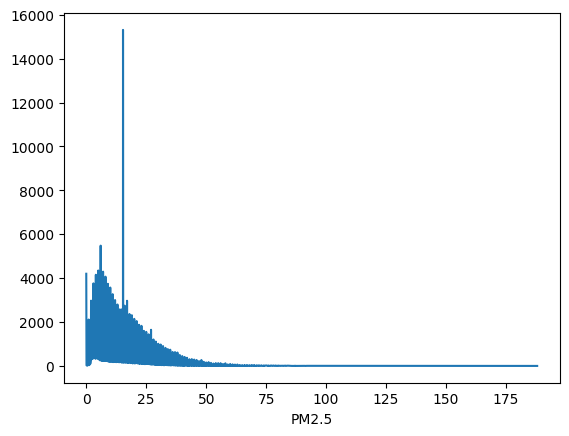

In [7]:
df_polutante['PM2.5'].value_counts().sort_index().plot.line()


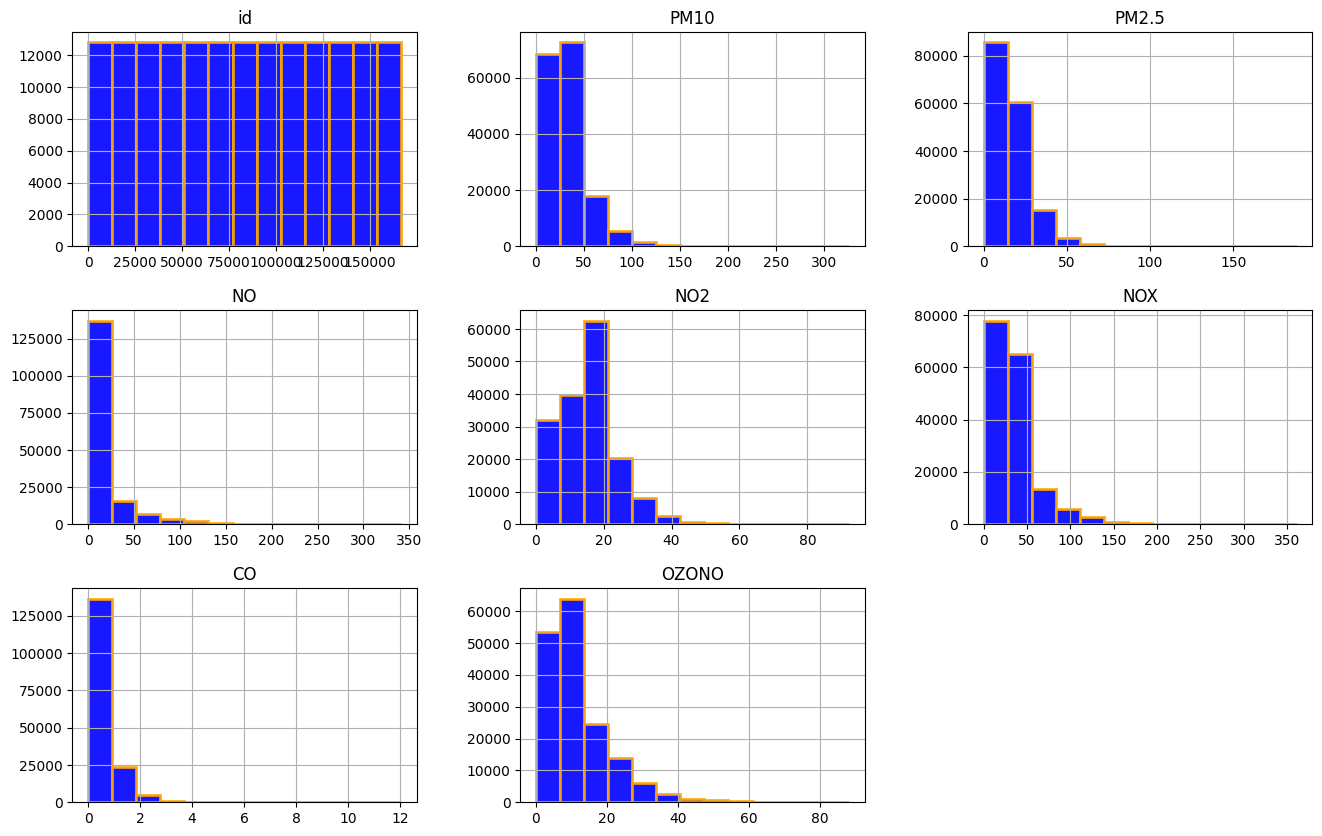

In [8]:
df_polutante.hist(figsize=(16,10),facecolor='blue', alpha=0.9, bins=13, edgecolor='orange', linewidth=2)
plt.show()

,PM10,PM2.5,NO,NO2,NOX,CO,OZONO
PM10,1.000000,0.759342,0.263510,0.334275,0.338827,0.459410,-0.032089
PM2.5,0.759342,1.000000,0.278223,0.388406,0.368550,0.504225,-0.053072
NO,0.263510,0.278223,1.000000,0.191043,0.952026,0.399122,-0.278493
NO2,0.334275,0.388406,0.191043,1.000000,0.477759,0.382669,-0.312026
NOX,0.338827,0.368550,0.952026,0.477759,1.000000,0.475027,-0.345144
CO,0.459410,0.504225,0.399122,0.382669,0.475027,1.000000,-0.259212
OZONO,-0.032089,-0.053072,-0.278493,-0.312026,-0.345144,-0.259212,1.000000


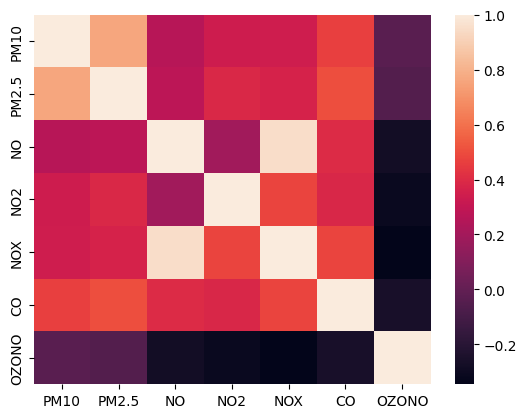

In [9]:
#Correlation Matrix
del(df_polutante['id'])
corr = df_polutante.corr()
corr = (corr)
sns.heatmap(corr, 
            xticklabels=corr.columns.values,
            yticklabels=corr.columns.values)
corr

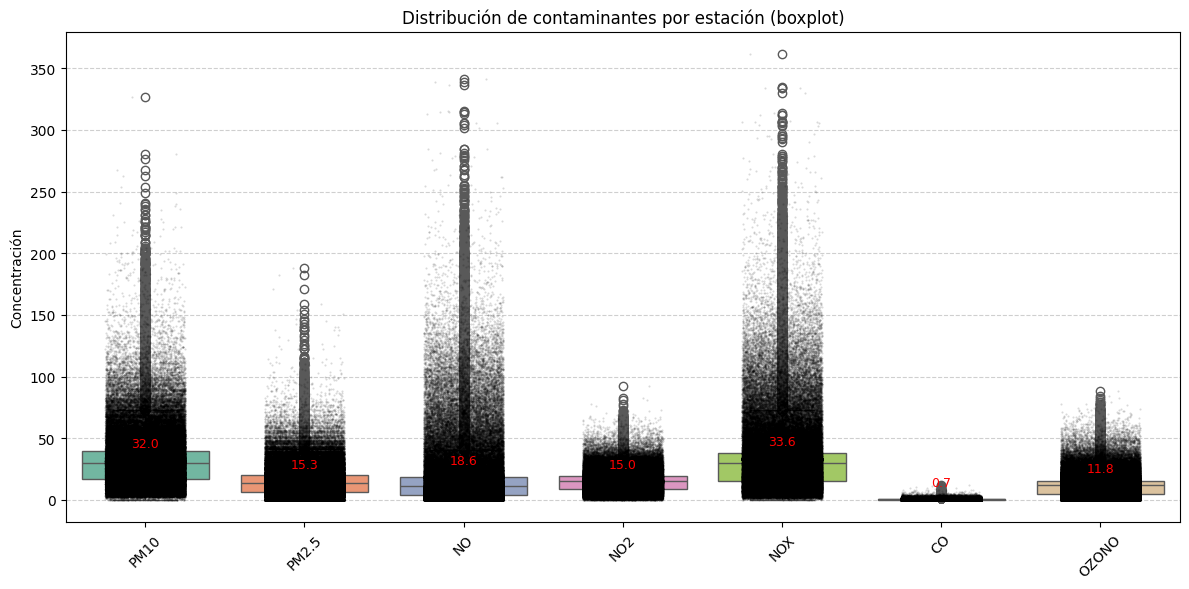

In [10]:
# Boxplot de la distribución de cada contaminante con medias anotadas
plt.figure(figsize=(12,6))
sns.boxplot(data=df_polutante, palette='Set2')
sns.stripplot(data=df_polutante, color='k', alpha=0.15, size=1.5, jitter=0.25)

means = df_polutante.mean()
y_range = df_polutante.max().max() - df_polutante.min().min()
offset = y_range * 0.03

for i, (col, m) in enumerate(means.items()):
    plt.text(i, m + offset, f'{m:.1f}', ha='center', color='red', fontsize=9)

plt.title('Distribución de contaminantes por estación (boxplot)')
plt.ylabel('Concentración')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()